# België: wegen en ongevalslocaties met GeoPandas
## tl;dr
Dit notebook onderzoekt het wegennet, de ruimtelijke spreiding van geregistreerde letselongevallen en de kwaliteit van de coördinaten. De berekende kernpunten staan bij de resultaten en in `tables/`.

## Samenvatting van de uitgevoerde run
**Uitgevoerde resultaten:** 33.830 bruikbare kaartpunten in 2024 (94.2% van het kaartbestand). De tien drukste rastercellen bevatten 17.6% van die punten. Over 2017–2024 zijn 2 onmogelijke coördinaten en 1 punten buiten de 1-km-grensbuffer uitgesloten van de kaarten; de brondata zijn behouden.

## Context & Methods
We tonen **2024** in detail en gebruiken 2017–2024 om de dekking te beoordelen. Kaartpunten zijn registraties uit `accident_map`, geen koppeling met de andere facttabellen.

### Key Assumptions
- Broncoördinaten worden geïnterpreteerd als **Belgian Lambert 72 (EPSG:31370)**. Dit wordt ruimtelijk gecontroleerd tegenover België; de lokale bron bevatte geen CRS-declaratie. De verificatie is een plausibiliteitstoets, geen bewijs van landmeetkundige precisie.
- Landgrens: Eurostat/GISCO 2024, schaal 1:1 miljoen. Wegen: © OpenStreetMap-bijdragers via Geofabrik, snapshot **1 januari 2025**, ODbL. De wegen zijn een contextlaag en geen verkeersvolume-noemer.
- We gebruiken de nationale grens met een **1 km buffer** voor de plausibiliteitscontrole vanwege grensvereenvoudiging. Punten buiten de buffer en onmogelijke coördinaten blijven in de brondataset, maar worden niet geplot.
- Concentraties tonen aantallen; zonder gereden kilometers of verkeersintensiteit zijn dit **geen risicoscores** of bewezen gevaarlijke wegen.
- De [Statbel-bronpagina](https://statbel.fgov.be/nl/open-data/geolocalisatie-van-de-verkeersongevallen-2017-2024) meldt een verbetering van geolokalisatie vanaf 2022. Kaarttrends mogen niet zonder dekkingscontrole worden geïnterpreteerd.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

BASE = Path.cwd()
if not (BASE / 'reference_data').exists():
    BASE = BASE / 'analysis_notebooks'
assert (BASE / 'reference_data').exists(), 'Start Jupyter in group_assignment or analysis_notebooks.'
ROOT = BASE.parent
GOLD = ROOT / 'data' / 'gold'
FIG = BASE / 'figures'; FIG.mkdir(exist_ok=True)
TABLES = BASE / 'tables'; TABLES.mkdir(exist_ok=True)
YEAR = 2024
BLUE, ORANGE, GREY = '#175A78', '#D76B32', '#657581'
plt.rcParams.update({'figure.figsize':(12,7),'figure.dpi':110,'savefig.dpi':200,
 'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':17,'axes.labelsize':11,
 'axes.spines.top':False,'axes.spines.right':False,'axes.edgecolor':'#BBC4CA',
 'axes.titleweight':'bold','axes.labelcolor':'#243440','text.color':'#243440',
 'xtick.color':'#465662','ytick.color':'#465662','figure.facecolor':'white'})
def number(v): return f'{v:,.0f}'.replace(',', '.')
def export(fig, name, source):
    fig.text(0.015, 0.015, source, fontsize=8, color=GREY)
    fig.savefig(FIG / f'{name}.png', bbox_inches='tight', facecolor='white')
    fig.savefig(FIG / f'{name}.svg', bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)
def load(name): return pd.read_parquet(GOLD/name/f'{name}.parquet')

## Data
### 1. Lokale bronnen en geometrie laden

In [2]:
import geopandas as gpd
from shapely.geometry import box
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm
REF = BASE/'reference_data'
country = gpd.read_file(REF/'belgium_2024.geojson').to_crs(31370)
assert country.geometry.is_valid.all()
border = country.geometry.union_all()
road_cache = REF/'roads_belgium.parquet'
if road_cache.exists():
    roads = gpd.read_parquet(road_cache)
else:
    roads = gpd.read_file(REF/'roads/gis_osm_roads_free_1.shp',
                          columns=['osm_id','fclass','name','ref','geometry']).to_crs(31370)
    # Spatial index restricts the candidates; only border-crossing segments need clipping.
    import shapely
    roads = roads.iloc[roads.sindex.query(border,predicate='intersects')].copy()
    shapely.prepare(border)
    crossing = ~shapely.contains(border,roads.geometry.array)
    roads.loc[crossing,'geometry'] = roads.loc[crossing].geometry.intersection(border)
    roads = roads[~roads.geometry.is_empty].copy()
    roads.to_parquet(road_cache,index=False)
assert roads.crs == country.crs
raw = load('accident_map')
display(pd.DataFrame({'bron':['Kaartregistraties','OSM-wegsegmenten'],
                      'rijen':[len(raw),len(roads)]}))

,bron,rijen
0,Kaartregistraties,289532
1,OSM-wegsegmenten,1364891


### 2. Coördinaten valideren en uitgesloten rijen bewaren

In [3]:
has_xy = raw[['MS_X_COORD','MS_Y_COORD']].notna().all(axis=1)
# Ruime Lambert-72 box rond België, vóór het aanmaken van geometrieën.
plausible = has_xy & raw.MS_X_COORD.between(0,300000) & raw.MS_Y_COORD.between(0,300000)
points = gpd.GeoDataFrame(raw.loc[plausible].copy(),
    geometry=gpd.points_from_xy(raw.loc[plausible,'MS_X_COORD'],raw.loc[plausible,'MS_Y_COORD']),crs=31370)
inside = points.geometry.intersects(border.buffer(1000))
raw['geo_status'] = 'ontbrekende_coordinaten'
raw.loc[has_xy & ~plausible,'geo_status'] = 'onmogelijke_coordinaten'
raw.loc[points.index,'geo_status'] = np.where(inside,'bruikbaar','buiten_belgie_buffer')
points = points.loc[inside].copy()
assert points._record_id.is_unique
assert len(points) == (raw.geo_status=='bruikbaar').sum()
exceptions = raw.loc[raw.geo_status!='bruikbaar',
    ['_record_id','_source_row','analysis_year','CD_NIS','MS_X_COORD','MS_Y_COORD','geo_status']]
exceptions.to_csv(TABLES/'geo_uitgesloten.csv',index=False)
coverage = pd.crosstab(raw.analysis_year,raw.geo_status).reindex(
    columns=['bruikbaar','ontbrekende_coordinaten','onmogelijke_coordinaten','buiten_belgie_buffer'],fill_value=0)
coverage['totaal_kaart'] = coverage.sum(axis=1)
coverage['dekking_pct'] = 100*coverage.bruikbaar/coverage.totaal_kaart
accidents = load('road_accidents')
coverage['totaal_ongevallen'] = accidents.groupby('analysis_year').MS_ACCT.sum()
coverage['verschil_kaart_totaal'] = coverage.totaal_kaart - coverage.totaal_ongevallen
coverage.to_csv(TABLES/'kaartdekking_per_jaar.csv')
display(coverage.round(2))
display(Markdown(f"**Controle:** {number(len(points))} punten bruikbaar; {number((~has_xy).sum())} zonder coördinaten; "
 f"{number((has_xy & ~plausible).sum())} met onmogelijke waarden; {number((~inside).sum())} buiten de grensbuffer."))
# Maak de CRS-aanname inspecteerbaar met een kleine, herkenbare steekproef.
display(points[['TX_MUNTY_COLLISION_NL','geometry']].head(5).to_crs(4326))

geo_status,bruikbaar,ontbrekende_coordinaten,onmogelijke_coordinaten,buiten_belgie_buffer,totaal_kaart,dekking_pct,totaal_ongevallen,verschil_kaart_totaal
analysis_year,,,,,,,,
2017,32217,5808,0,0,38025,84.73,38025,0
2018,31983,6470,0,0,38453,83.17,38453,0
2019,31216,6502,0,1,37719,82.76,37719,0
2020,24514,5737,0,0,30251,81.04,30251,0
2021,28334,6326,0,0,34660,81.75,34660,0
2022,35884,1764,2,0,37650,95.31,37650,0
2023,35670,1188,0,0,36858,96.78,36858,0
2024,33830,2086,0,0,35916,94.19,35932,-16


**Controle:** 253.648 punten bruikbaar; 35.881 zonder coördinaten; 2 met onmogelijke waarden; 1 buiten de grensbuffer.

,TX_MUNTY_COLLISION_NL,geometry
0,Schaarbeek,POINT (4.36496 50.86222)
1,Antwerpen,POINT (4.4012 51.19667)
2,Genk,POINT (5.49319 50.96625)
3,Anderlecht,POINT (4.30236 50.82594)
4,Ranst,POINT (4.68682 51.24226)


## Results
### 3. Belgisch wegennet
De nationale kaart toont snelwegen en hoofd-/secundaire wegen. Lokale straten staan in de cache en in de detailkaart. Zo blijft het landelijk patroon leesbaar.

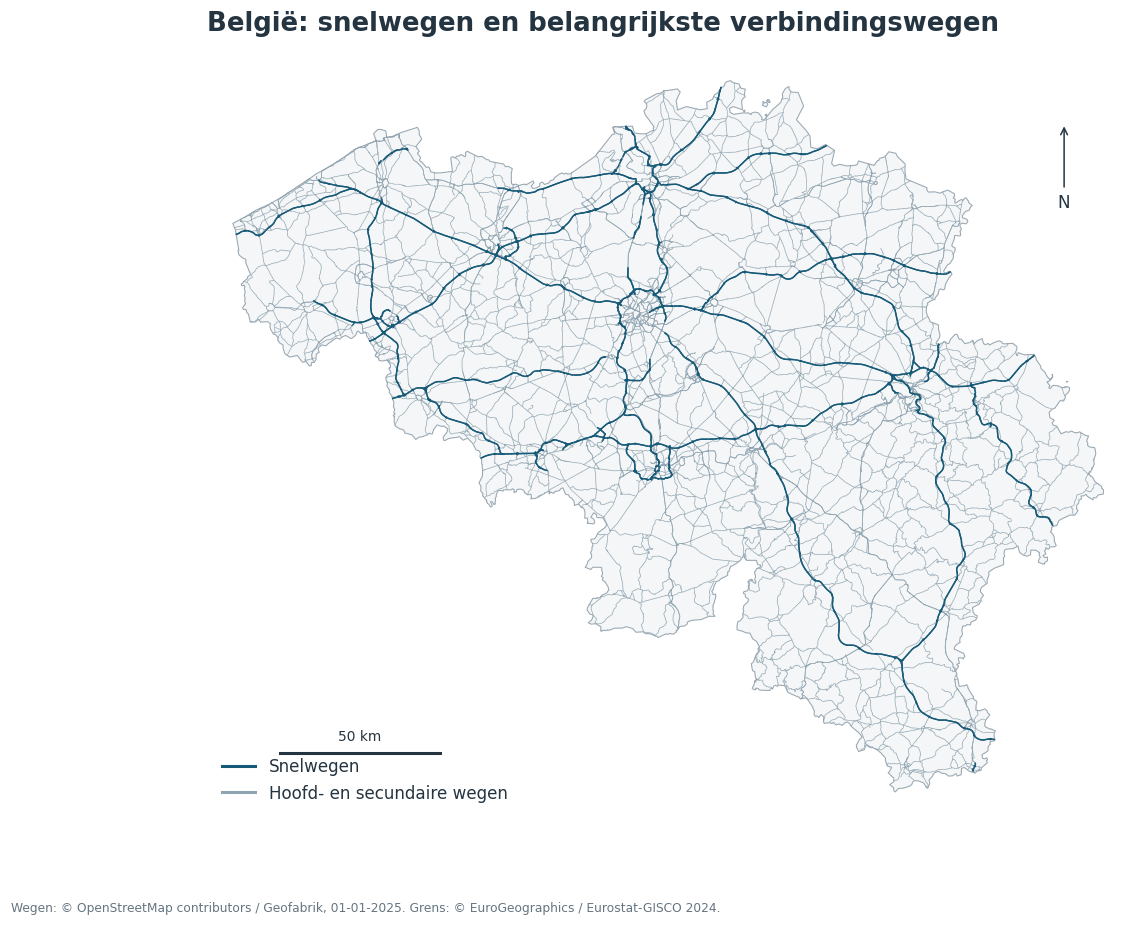

In [4]:
major_classes = ['motorway','motorway_link','trunk','trunk_link','primary','primary_link','secondary','secondary_link']
major = roads[roads.fclass.isin(major_classes)]
motorways = major[major.fclass.isin(['motorway','motorway_link'])]
other = major[~major.fclass.isin(['motorway','motorway_link'])]
def base_map(ax):
    country.plot(ax=ax,color='#F4F6F7',edgecolor='#9AA8B2',linewidth=.7)
    ax.set_aspect('equal'); ax.set_axis_off()
    xmin,ymin,xmax,ymax=country.total_bounds
    ax.set_xlim(xmin-8000,xmax+8000); ax.set_ylim(ymin-8000,ymax+8000)
def scale_bar(ax):
    xmin,ymin,xmax,ymax=country.total_bounds
    ax.plot([xmin+15000,xmin+65000],[ymin+12000,ymin+12000],color='#243440',lw=2)
    ax.text(xmin+40000,ymin+16000,'50 km',ha='center',fontsize=9)
    ax.annotate('N',xy=(.93,.91),xytext=(.93,.80),xycoords='axes fraction',ha='center',arrowprops={'arrowstyle':'->','color':'#243440'})
fig,ax=plt.subplots(figsize=(12,9))
base_map(ax)
other.plot(ax=ax,color='#8FA4B1',linewidth=.45)
motorways.plot(ax=ax,color=BLUE,linewidth=.9)
scale_bar(ax)
ax.set_title('België: snelwegen en belangrijkste verbindingswegen',loc='left',pad=16)
ax.legend(handles=[Line2D([0],[0],color=BLUE,lw=2,label='Snelwegen'),
 Line2D([0],[0],color='#8FA4B1',lw=2,label='Hoofd- en secundaire wegen')],loc='lower left',frameon=False)
export(fig,'01_belgie_wegennet','Wegen: © OpenStreetMap contributors / Geofabrik, 01-01-2025. Grens: © EuroGeographics / Eurostat-GISCO 2024.')

### 4. Geografische dekking door de jaren
De noemer is alle registraties in het kaartbestand van dat jaar. Het verschil tegenover MS_ACCT staat in de tabel; de twee bronnen worden niet geforceerd gelijk gemaakt.

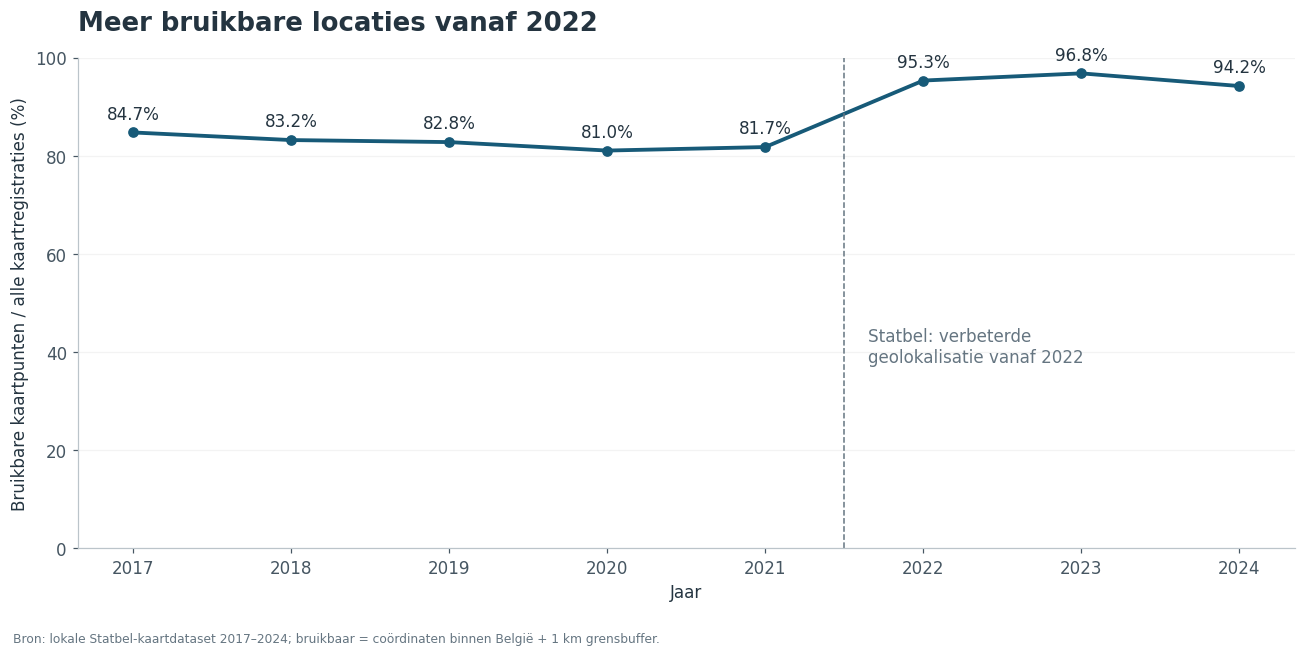

In [5]:
fig,ax=plt.subplots(figsize=(12,6))
ax.plot(coverage.index,coverage.dekking_pct,color=BLUE,marker='o',lw=2.5)
ax.set(ylim=(0,100),ylabel='Bruikbare kaartpunten / alle kaartregistraties (%)',xlabel='Jaar')
ax.set_xticks(coverage.index)
ax.axvline(2021.5,color=GREY,ls='--',lw=1)
ax.text(2021.65,38,'Statbel: verbeterde\ngeolokalisatie vanaf 2022',fontsize=11,color=GREY)
for yr,r in coverage.iterrows(): ax.annotate(f'{r.dekking_pct:.1f}%',(yr,r.dekking_pct),xytext=(0,9),textcoords='offset points',ha='center')
ax.set_title('Meer bruikbare locaties vanaf 2022',loc='left',pad=18)
ax.grid(axis='y',alpha=.15)
fig.tight_layout(rect=(0,.05,1,1))
export(fig,'02_kaartdekking','Bron: lokale Statbel-kaartdataset 2017–2024; bruikbaar = coördinaten binnen België + 1 km grensbuffer.')

### 5. Concentraties in een vast raster
Vierkanten van 5 × 5 km in EPSG:31370, verankerd op gehele veelvouden van 5.000 meter. Alleen cellen met waarnemingen krijgen kleur. Dit zijn aantallen geregistreerde locaties, geen risico per weggebruiker.

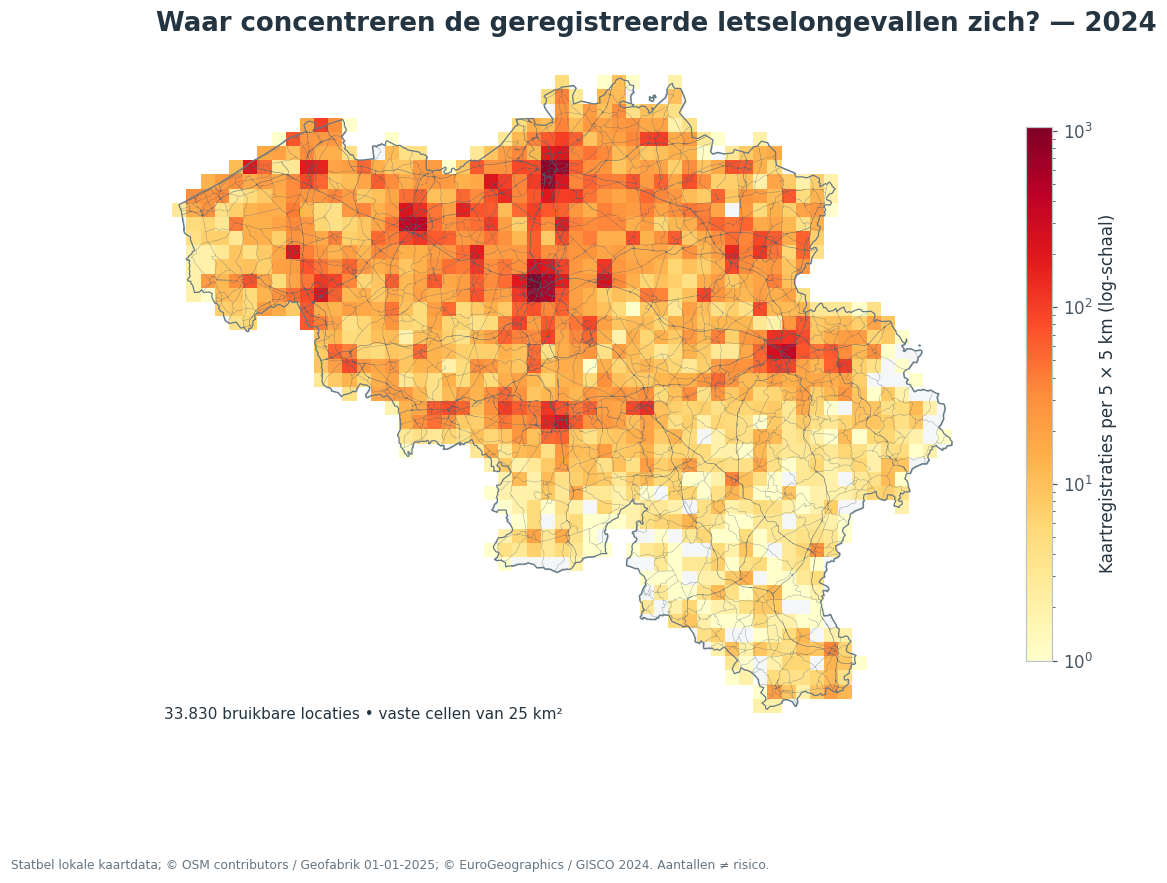

,grid_x,grid_y,observaties,aandeel_pct
445,29,34,1048,3.10
483,30,42,843,2.49
482,30,41,666,1.97
444,29,33,663,1.96
515,31,42,628,1.86
475,30,34,498,1.47
474,30,33,465,1.37
252,21,38,393,1.16
231,20,38,369,1.09
1063,47,29,366,1.08


In [6]:
selected=points[points.analysis_year==YEAR].copy()
CELL=5000
selected['grid_x']=(selected.geometry.x//CELL).astype(int)
selected['grid_y']=(selected.geometry.y//CELL).astype(int)
counts=selected.groupby(['grid_x','grid_y']).size().rename('observaties').reset_index()
grid=gpd.GeoDataFrame(counts,geometry=[box(x*CELL,y*CELL,(x+1)*CELL,(y+1)*CELL)
    for x,y in zip(counts.grid_x,counts.grid_y)],crs=31370)
assert int(grid.observaties.sum())==len(selected)
grid.to_parquet(TABLES/'concentraties_5km_2024.parquet',index=False)
grid.drop(columns='geometry').sort_values('observaties',ascending=False).to_csv(TABLES/'concentraties_5km_2024.csv',index=False)
fig,ax=plt.subplots(figsize=(12,9)); base_map(ax)
grid.plot(ax=ax,column='observaties',cmap='YlOrRd',norm=LogNorm(vmin=1,vmax=grid.observaties.max()),
    linewidth=0,legend=True,legend_kwds={'label':'Kaartregistraties per 5 × 5 km (log-schaal)','shrink':.7})
major.plot(ax=ax,color='#526877',linewidth=.25,alpha=.7)
country.boundary.plot(ax=ax,color='#637784',linewidth=.8)
ax.set_title(f'Waar concentreren de geregistreerde letselongevallen zich? — {YEAR}',loc='left',pad=16)
ax.text(.01,.02,f'{number(len(selected))} bruikbare locaties • vaste cellen van 25 km²',transform=ax.transAxes,fontsize=10)
export(fig,'03_concentraties_2024','Statbel lokale kaartdata; © OSM contributors / Geofabrik 01-01-2025; © EuroGeographics / GISCO 2024. Aantallen ≠ risico.')
top_cells=grid.nlargest(10,'observaties').copy()
top_cells['aandeel_pct']=100*top_cells.observaties/len(selected)
display(top_cells.drop(columns='geometry').round(2))

### 6. Detailvoorbeeld: Brussel
Alleen een vast uitsnedevenster rond Brussel; dit is geen administratieve afbakening van het gewest. Punten worden niet automatisch aan het dichtstbijzijnde wegsegment gekoppeld.

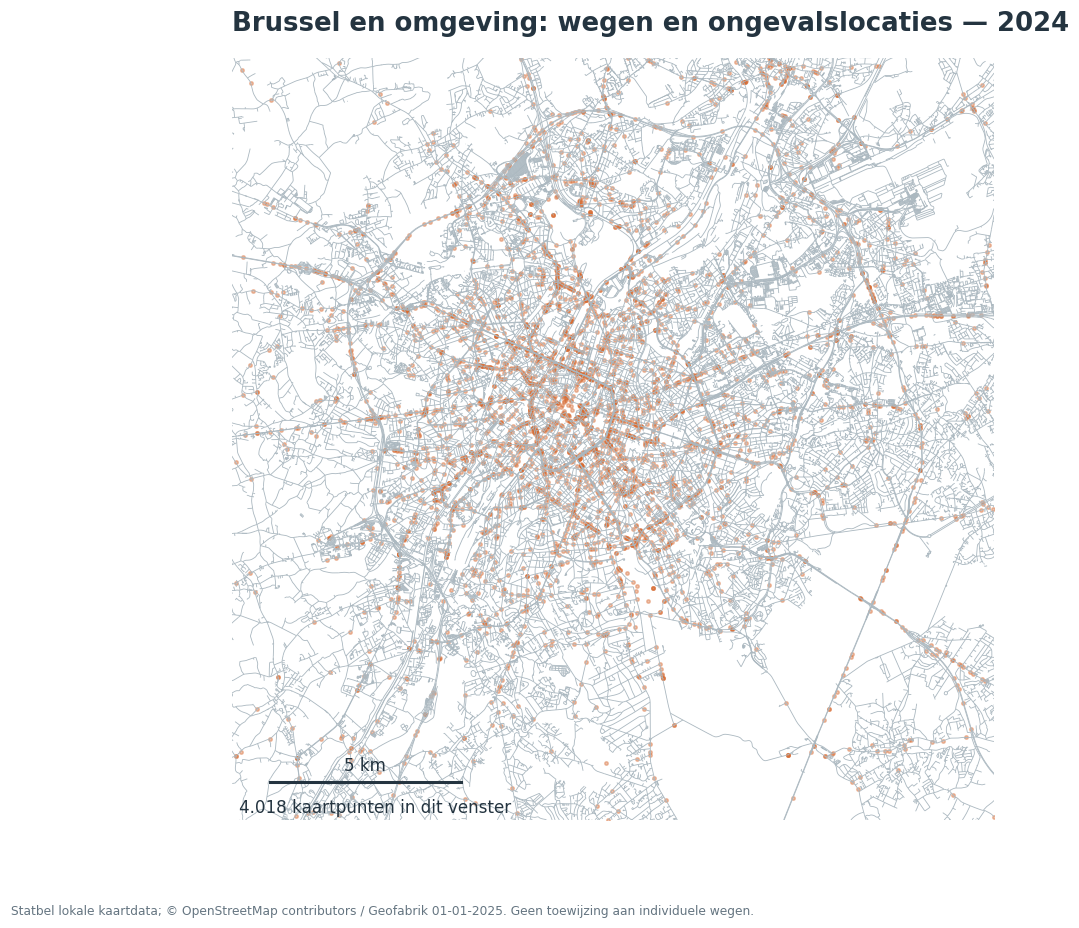

**Resultaat:** de tien drukste rastercellen bevatten 17.6% van de bruikbare kaartregistraties van 2024. Dit meet ruimtelijke concentratie; het is geen rangschikking van verkeersrisico.

In [7]:
window=box(140000,160000,160000,180000)
local_roads=roads[roads.intersects(window)].copy()
local_roads.geometry=local_roads.geometry.intersection(window)
drivable=['motorway','motorway_link','trunk','trunk_link','primary','primary_link','secondary','secondary_link',
          'tertiary','tertiary_link','residential','unclassified','living_street','service']
local_roads=local_roads[local_roads.fclass.isin(drivable)]
local_points=selected[selected.intersects(window)]
fig,ax=plt.subplots(figsize=(11,9))
local_roads.plot(ax=ax,color='#ABB8C0',linewidth=.55)
local_points.plot(ax=ax,color=ORANGE,markersize=5,alpha=.4,rasterized=True)
ax.set(xlim=(140000,160000),ylim=(160000,180000)); ax.set_aspect('equal'); ax.set_axis_off()
ax.set_title(f'Brussel en omgeving: wegen en ongevalslocaties — {YEAR}',loc='left',pad=18)
ax.text(.01,.01,f'{number(len(local_points))} kaartpunten in dit venster',transform=ax.transAxes)
ax.plot([141000,146000],[161000,161000],color='#243440',lw=2); ax.text(143500,161300,'5 km',ha='center')
export(fig,'04_brussel_detail','Statbel lokale kaartdata; © OpenStreetMap contributors / Geofabrik 01-01-2025. Geen toewijzing aan individuele wegen.')
geo_summary={'usable_points':len(points),'selected_year':YEAR,'selected_points':len(selected),
 'coverage_2017':float(coverage.loc[2017,'dekking_pct']),'coverage_2024':float(coverage.loc[2024,'dekking_pct']),
 'missing_coordinates':int((~has_xy).sum()),'impossible_coordinates':int((has_xy & ~plausible).sum()),
 'outside_border':int((~inside).sum()),'map_total_difference_2024':int(coverage.loc[2024,'verschil_kaart_totaal']),
 'top10_cell_share':float(top_cells.aandeel_pct.sum()),'road_segments':len(roads)}
(TABLES/'geo_summary.json').write_text(json.dumps(geo_summary,indent=2),encoding='utf-8')
display(Markdown(f"**Resultaat:** de tien drukste rastercellen bevatten {geo_summary['top10_cell_share']:.1f}% van de bruikbare kaartregistraties van {YEAR}. "
 'Dit meet ruimtelijke concentratie; het is geen rangschikking van verkeersrisico.'))

## Takeaways
1. Het wegennet en de locaties zijn met GeoPandas in één geprojecteerd stelsel gezet; de wegenlaag is daadwerkelijk vectorgeometrie.
2. Vergelijk kaartjaren altijd samen met de geolokalisatiedekking. De verbetering vanaf 2022 beperkt directe hotspot-trendvergelijkingen.
3. Coördinatenfouten worden zichtbaar gemaakt en uitgesloten van kaarten, zonder gold of de bron te wijzigen. Bekijk `tables/geo_uitgesloten.csv`.
4. Het kaartbestand telt in 2024 niet exact evenveel registraties als `SUM(MS_ACCT)`. Gebruik de algemene ongevalstabel voor nationale trends en de kaartbron voor ruimtelijke patronen.
5. Een volgende stap is onderzoek op wegsegmentniveau met verkeersintensiteiten en gevalideerde ongeval-wegkoppelingen. De huidige kaarten rechtvaardigen geen causale claims.

Bronnen: [Statbel geolokalisatie](https://statbel.fgov.be/nl/open-data/geolocalisatie-van-de-verkeersongevallen-2017-2024), [Geofabrik België](https://download.geofabrik.de/europe/belgium.html), [GISCO](https://gisco-services.ec.europa.eu/distribution/v2/countries/), [OSM-licentie](https://www.openstreetmap.org/copyright). Downloads, URL's en hashes: `reference_data/sources.json`. De notebooks draaien na download offline.